# COMP6010 Assignment — Part B: Bayesian Learning with a Beta Prior

**Student:** Satria Pamungkas &nbsp;|&nbsp; **Student ID:** 21522611

**Scenario — a fruit-picking robot.** A robot uses a soft gripper to pick fruit without dropping or
damaging it. Let $\theta$ be its unknown success probability. Attempt $i$ has $X_i = 1$ on success
and $X_i = 0$ otherwise, and attempts are conditionally independent given a fixed $\theta$. The
robot settings and evaluation conditions are assumed unchanged across the three batches.

Initial prior: $\theta \sim \mathrm{Beta}(2,3)$. The observations below are the hypothetical values
supplied in the brief; **each row is new attempts, not cumulative counts.**

| Batch | Attempts | Successes | Failures |
|---|---|---|---|
| 1 | 10 | 6 | 4 |
| 2 | 20 | 16 | 4 |
| 3 | 70 | 63 | 7 |

**Contents.** B1 formulation · B2 posterior updating · B3 uncertainty and decision · B4 prior
sensitivity.

In [1]:
%pip install -r requirements_frozen.txt

Defaulting to user installation because normal site-packages is not writeable
  Using cached jupyter_events-0.9.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached jupyter_lsp-2.2.2-py3-none-any.whl.metadata (1.8 kB)
  Using cached jupyter_client-8.6.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached jupyter_core-5.7.1-py3-none-any.whl.metadata (3.4 kB)
  Using cached jupyter_server-2.12.5-py3-none-any.whl.metadata (8.4 kB)
  Using cached jupyter_server_terminals-0.5.2-py3-none-any.whl.metadata (5.6 kB)
  Using cached jupyterlab-4.0.12-py3-none-any.whl.metadata (15 kB)
  Using cached jupyterlab_server-2.25.2-py3-none-any.whl.metadata (5.9 kB)
  Using cached matplotlib-3.10.8-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached matplotlib_inline-0.1.6-py3-none-any.whl.metadata (2.8 kB)
  Using cached nbconvert-7.14.2-py3-none-any.whl.metadata (7.7 kB)
  Using cached notebook-7.0.7-py3-none-any.whl.metadata (10 kB)
  Using cached notebook_shim-0.2.3

In [2]:
import numpy as np
import pandas as pd
from scipy import stats, integrate
import matplotlib.pyplot as plt
import json, os, sys, platform

def find_results_dir(part="partB"):
    here = os.path.abspath(os.getcwd())
    for cand in (os.path.join(here, "..", "results", part),
                 os.path.join(here, "results", part)):
        cand = os.path.abspath(cand)
        if os.path.isdir(os.path.dirname(cand)):
            os.makedirs(cand, exist_ok=True)
            return cand
    os.makedirs(os.path.join(here, "results", part), exist_ok=True)
    return os.path.abspath(os.path.join(here, "results", part))

RES = find_results_dir("partB")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 170, "display.precision", 6)

SEED = 20260910                    # stated random seed, reused throughout Part B
N_DRAWS = 200_000                  # >= 10,000 as required

ALPHA0, BETA0 = 2.0, 3.0           # initial prior Beta(2,3)
BATCHES = [{"batch": 1, "n": 10, "s": 6,  "f": 4},
           {"batch": 2, "n": 20, "s": 16, "f": 4},
           {"batch": 3, "n": 70, "s": 63, "f": 7}]
THRESHOLD = 0.80
DECISION_LEVEL = 0.95

for b in BATCHES:
    assert b["s"] + b["f"] == b["n"], "batch counts inconsistent"
TOTAL_N = sum(b["n"] for b in BATCHES)
TOTAL_S = sum(b["s"] for b in BATCHES)
print(f"pooled data: N = {TOTAL_N} attempts, s = {TOTAL_S} successes, "
      f"f = {TOTAL_N - TOTAL_S} failures")
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | scipy {stats.__name__} "
      f"{__import__('scipy').__version__}")
print(f"seed = {SEED}, posterior draws = {N_DRAWS:,}")

pooled data: N = 100 attempts, s = 85 successes, f = 15 failures
python 3.10.12 | numpy 1.26.4 | scipy scipy.stats 1.13.0
seed = 20260910, posterior draws = 200,000


/usr/local/lib/python3.10/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## B1. Formulate the learning problem

### Why Bernoulli, and why Beta

**Bernoulli for the outcome.** Each grasp attempt has exactly two possible results — the fruit is
picked cleanly or it is not. The Bernoulli distribution is the unique distribution on
$\{0,1\}$, with one parameter, so it is the natural likelihood for a single attempt:

$$P(X_i = x \mid \theta) = \theta^{x}(1-\theta)^{1-x}, \qquad x \in \{0,1\}$$

Given $n$ conditionally independent attempts with $s$ successes, the likelihood is a product that
depends on the data only through $s$ and $n$ (these are *sufficient statistics*):

$$P(\mathcal{D} \mid \theta) = \prod_{i=1}^{n}\theta^{x_i}(1-\theta)^{1-x_i} = \theta^{s}(1-\theta)^{n-s}$$

**Beta for the parameter.** $\theta$ is not an outcome we observe; it is an unknown *continuous*
quantity in $(0,1)$. A single number cannot express our uncertainty about it, so we place a
probability density on it. The Beta family is supported exactly on $(0,1)$ — the right support for a
probability — and is flexible enough to encode anything from complete ignorance to a strong belief:

$$f(\theta) = \frac{\theta^{\alpha-1}(1-\theta)^{\beta-1}}{B(\alpha,\beta)}, \qquad 0 < \theta < 1$$

The decisive property is **conjugacy**: the Beta kernel $\theta^{\alpha-1}(1-\theta)^{\beta-1}$ has
the same algebraic form as the Bernoulli likelihood $\theta^{s}(1-\theta)^{n-s}$, so multiplying them
returns another Beta. Updating is therefore exact arithmetic on two numbers, with no numerical
integration required. $B(\alpha,\beta)$ is only the normalising constant that makes the density
integrate to one; it does not depend on $\theta$ and never needs to be derived here.

$\alpha$ and $\beta$ are **prior shape parameters, not observed data.** They behave like
$\alpha - 1$ pseudo-successes and $\beta - 1$ pseudo-failures, which is a useful intuition for
comparing prior strength against sample size, but they are not counts of anything that happened.
The initial prior $\mathrm{Beta}(2,3)$ has mean $2/5 = 0.4$ — a mildly pessimistic starting belief
carrying about as much weight as 3 real attempts.

### Outcome $X_i$ versus parameter $\theta$

| | $X_i$ | $\theta$ |
|---|---|---|
| what it is | observed outcome of one attempt | unknown success probability of the robot |
| type | discrete, $\{0,1\}$ | continuous, $(0,1)$ |
| described by | probability **mass** $P(X_i = x \mid \theta)$ | probability **density** $f(\theta)$ |
| how many | one per attempt, 100 in total | one, fixed and shared by all attempts |
| learned by | it is observed directly | inferred; we only ever get a distribution over it |

A density value is **not** a probability: $f(0.8) = 4.6$ is perfectly legitimate, whereas
$P(\theta = 0.8) = 0$ exactly, because a continuous variable assigns zero probability to any single
point. Only *intervals* have probability, which is why B3 asks for $P(\theta > 0.8 \mid \mathcal{D})$
rather than a density value.

### Graphical model and conditional independence

```
              θ  ~ Beta(α, β)          θ is a single shared parent
        ┌─────┼─────┬── ... ──┐
        ▼     ▼     ▼         ▼
       X₁    X₂    X₃  ...  X₁₀₀      each Xᵢ | θ ~ Bernoulli(θ)
```

This is a plate model: $\theta$ is the single parent of every observation, and the observations have
no edges among themselves. The joint is

$$f(\theta, x_1,\dots,x_n) = f(\theta) \prod_{i=1}^{n} P(x_i \mid \theta)$$

**Conditional independence.** The factorisation says $X_i \perp X_j \mid \theta$ for $i \ne j$:
*once* $\theta$ is fixed, knowing that attempt 3 succeeded tells us nothing more about attempt 4.
But the $X_i$ are **not marginally independent.** Integrating $\theta$ out,
$P(x_1,\dots,x_n) = \int f(\theta)\prod_i P(x_i\mid\theta)\,d\theta$, does not factorise, because
$\theta$ is a common parent — observing successes shifts our belief about $\theta$, which changes
what we expect of every future attempt. This is exactly the same collider-free "common cause"
dependence seen in Part A, and it is what makes learning possible: if the attempts were marginally
independent, data could not inform us about $\theta$.

In [3]:
# Numerical demonstration: X_i are conditionally independent given theta but NOT marginally so.
rng = np.random.default_rng(SEED)
th = rng.beta(ALPHA0, BETA0, 400_000)                     # theta ~ prior
x1 = (rng.random(400_000) < th).astype(int)               # X1 | theta
x2 = (rng.random(400_000) < th).astype(int)               # X2 | theta, same theta

print("MARGINAL (theta integrated out):")
print(f"  P(X1=1)            = {x1.mean():.4f}   (prior mean = {ALPHA0/(ALPHA0+BETA0):.4f})")
print(f"  P(X2=1)            = {x2.mean():.4f}")
print(f"  P(X1=1, X2=1)      = {(x1*x2).mean():.4f}")
print(f"  P(X1=1)P(X2=1)     = {x1.mean()*x2.mean():.4f}   <- differs => NOT independent")
print(f"  P(X2=1 | X1=1)     = {x2[x1==1].mean():.4f}")
print(f"  P(X2=1 | X1=0)     = {x2[x1==0].mean():.4f}   <- X1 is informative about X2")

fixed = 0.55
xa = (rng.random(400_000) < fixed).astype(int)
xb = (rng.random(400_000) < fixed).astype(int)
print(f"\nCONDITIONAL on theta = {fixed} (held fixed):")
print(f"  P(Xb=1 | Xa=1)     = {xb[xa==1].mean():.4f}")
print(f"  P(Xb=1 | Xa=0)     = {xb[xa==0].mean():.4f}   <- equal => conditionally independent")

MARGINAL (theta integrated out):
  P(X1=1)            = 0.4001   (prior mean = 0.4000)
  P(X2=1)            = 0.3995
  P(X1=1, X2=1)      = 0.2001
  P(X1=1)P(X2=1)     = 0.1599   <- differs => NOT independent
  P(X2=1 | X1=1)     = 0.5000
  P(X2=1 | X1=0)     = 0.3326   <- X1 is informative about X2

CONDITIONAL on theta = 0.55 (held fixed):
  P(Xb=1 | Xa=1)     = 0.5506
  P(Xb=1 | Xa=0)     = 0.5496   <- equal => conditionally independent


### Why $X_1$ is informative about $X_2$ (reading the output above)

The simulation gives

| | value |
|---|---|
| $P(X_2=1 \mid X_1=1)$ | $\approx 0.50$ |
| $P(X_2=1 \mid X_1=0)$ | $\approx 0.33$ |
| $P(X_2=1)$ with no information | $\approx 0.40$ |

If $X_1$ told us nothing about $X_2$, all three numbers would be the same. They are not: seeing a
success on attempt 1 raises our expectation for attempt 2 from 0.40 to 0.50, and seeing a failure
lowers it to 0.33.

**The reason is that we do not know $\theta$.** Attempt 1 does not physically affect attempt 2. What
it changes is our *belief* about how good the robot is, and that belief is what we use to predict
attempt 2:

```
  X1 observed  ──►  belief about θ updated  ──►  prediction for X2 changes
```

An analogy: you are handed a robot and told nothing about it. If its first grasp succeeds, you
suspect it is a decent robot, so you expect the second grasp to succeed more often. If its first grasp
fails, you suspect it is a poor one. The two attempts are linked only through the shared unknown
$\theta$, which is the "common cause" in the graph.

**Where the exact numbers come from.** Observing one attempt is just a one-attempt Bayesian update
of the $\mathrm{Beta}(2,3)$ prior, and the prediction for $X_2$ is the mean of that updated Beta:

- $X_1 = 1$ (one success): $\mathrm{Beta}(2+1,\ 3) = \mathrm{Beta}(3,3)$, mean $= 3/6 = 0.500$
- $X_1 = 0$ (one failure): $\mathrm{Beta}(2,\ 3+1) = \mathrm{Beta}(2,4)$, mean $= 2/6 = 0.333$

These match the simulated $0.5000$ and $0.3326$. The same dependence shows up in the joint:
$P(X_1=1, X_2=1) = \mathbb{E}[\theta^2] = \frac{2\cdot 3}{5 \cdot 6} = 0.20$, which is larger than
$P(X_1=1)P(X_2=1) = 0.4 \times 0.4 = 0.16$. Two successes together are more likely than independence
would predict, because both are more likely when $\theta$ happens to be high.

**Why the dependence disappears when $\theta$ is fixed.** In the second half of the output,
$\theta = 0.55$ is known exactly. There is nothing left to learn about the robot, so $X_a$ cannot
change our belief, and $P(X_b=1 \mid X_a=1) \approx P(X_b=1 \mid X_a=0) \approx 0.55$. This is the
conditional independence $X_i \perp X_j \mid \theta$.

**Why this matters for Part B.** This marginal dependence is what makes learning work: past attempts
inform future ones *through* $\theta$. The posterior updates in B2 are this same idea applied to 100
attempts instead of one.

## B2. Update and compare estimates  *(3 marks)*

### Deriving the posterior form

Bayes' rule for a continuous parameter (densities, with the marginal likelihood as the constant):

$$f(\theta \mid \mathcal{D}) = \frac{P(\mathcal{D}\mid\theta)\, f(\theta)}{P(\mathcal{D})},
\qquad P(\mathcal{D}) = \int_0^1 P(\mathcal{D}\mid\theta) f(\theta)\, d\theta$$

Substituting the Bernoulli likelihood and Beta prior, and dropping every factor free of $\theta$
into the normalising constant:

$$f(\theta\mid\mathcal{D}) \;\propto\; \underbrace{\theta^{s}(1-\theta)^{n-s}}_{\text{likelihood}}
\cdot \underbrace{\theta^{\alpha-1}(1-\theta)^{\beta-1}}_{\text{prior}}
\;=\; \theta^{(\alpha+s)-1}(1-\theta)^{(\beta+n-s)-1}$$

The right-hand side is the kernel of a Beta density, so the normalising constant must be
$B(\alpha+s,\ \beta+n-s)$ and

$$\boxed{\;\theta \mid \mathcal{D} \;\sim\; \mathrm{Beta}(\alpha + s,\ \beta + n - s)\;}$$

Updating is just: add successes to $\alpha$, add failures to $\beta$.

### Why sequential and pooled updating must agree

Using each batch's posterior as the next batch's prior adds $(s_k, f_k)$ at every step, so after
three batches the parameters are $\alpha_0 + \sum_k s_k$ and $\beta_0 + \sum_k f_k$ — identical to
updating once with the pooled totals. This is a direct consequence of conditional independence given
$\theta$: the likelihood factorises across batches, and multiplication is order-independent. If the
two routes disagreed it would indicate an implementation error (typically re-using the *original*
prior at each step, or treating the table's rows as cumulative).

### Point estimates

$$\hat\theta_{\mathrm{ML}} = \frac{s}{n}, \qquad
\mathbb{E}[\theta \mid \mathcal{D}] = \frac{\alpha_n}{\alpha_n + \beta_n}, \qquad
\hat\theta_{\mathrm{MAP}} = \frac{\alpha_n - 1}{\alpha_n + \beta_n - 2} \;\;(\alpha_n,\beta_n > 1)$$

The MAP formula comes from setting the derivative of the log density to zero; it is the mode, which
differs from the mean whenever the posterior is skewed.

In [4]:
def beta_update(alpha, beta, s, f):
    """Conjugate Beta-Bernoulli update: add successes to alpha, failures to beta."""
    return alpha + s, beta + f

def posterior_summary(alpha, beta, label, n_cum, s_cum):
    """Point estimates and interval summaries for a Beta(alpha, beta) posterior."""
    d = stats.beta(alpha, beta)
    mode = (alpha - 1) / (alpha + beta - 2) if (alpha > 1 and beta > 1) else np.nan
    lo, hi = d.ppf(0.025), d.ppf(0.975)
    return {"stage": label, "alpha": alpha, "beta": beta,
            "cum_attempts": n_cum, "cum_successes": s_cum,
            "ML (s/n)": (s_cum / n_cum) if n_cum else np.nan,
            "posterior mean": alpha / (alpha + beta),
            "MAP (mode)": mode,
            "posterior sd": d.std(),
            "95% CI low": lo, "95% CI high": hi, "CI width": hi - lo,
            "P(theta > 0.8)": d.sf(THRESHOLD)}

# ---------------------------------------------------------------- sequential updating
rows = [posterior_summary(ALPHA0, BETA0, "prior Beta(2,3)", 0, 0)]
a, b = ALPHA0, BETA0
n_cum = s_cum = 0
seq_params = [(ALPHA0, BETA0)]
for bt in BATCHES:
    a, b = beta_update(a, b, bt["s"], bt["f"])
    n_cum += bt["n"]; s_cum += bt["s"]
    seq_params.append((a, b))
    rows.append(posterior_summary(a, b, f"after batch {bt['batch']}", n_cum, s_cum))

seq_df = pd.DataFrame(rows)
print("SEQUENTIAL UPDATING\n")
print(seq_df[["stage", "alpha", "beta", "cum_attempts", "cum_successes",
              "ML (s/n)", "posterior mean", "MAP (mode)", "posterior sd"]].to_string(index=False))
seq_df.to_csv(os.path.join(RES, "B2_sequential_updates.csv"), index=False)

A_FINAL, B_FINAL = a, b
POST = stats.beta(A_FINAL, B_FINAL)

SEQUENTIAL UPDATING

          stage  alpha  beta  cum_attempts  cum_successes  ML (s/n)  posterior mean  MAP (mode)  posterior sd
prior Beta(2,3)    2.0   3.0             0              0       NaN        0.400000    0.333333      0.200000
  after batch 1    8.0   7.0            10              6  0.600000        0.533333    0.538462      0.124722
  after batch 2   24.0  11.0            30             22  0.733333        0.685714    0.696970      0.077372
  after batch 3   87.0  18.0           100             85  0.850000        0.828571    0.834951      0.036606


In [5]:
# --------------------------------------- check 1: sequential == pooled
a_pool, b_pool = beta_update(ALPHA0, BETA0, TOTAL_S, TOTAL_N - TOTAL_S)
print(f"sequential final posterior : Beta({A_FINAL}, {B_FINAL})")
print(f"pooled-data posterior      : Beta({a_pool}, {b_pool})")
assert (a_pool, b_pool) == (A_FINAL, B_FINAL), "sequential and pooled updates disagree"
print("CHECK PASSED: identical, as conjugacy + conditional independence require.")
print(f"\n  alpha = {ALPHA0} + {TOTAL_S} = {A_FINAL}   "
      f"beta = {BETA0} + {TOTAL_N - TOTAL_S} = {B_FINAL}")

# --------------------------------------- check 2: closed form == numerical Bayes on a grid
grid = np.linspace(1e-6, 1 - 1e-6, 200_001)
log_post = ((ALPHA0 - 1) * np.log(grid) + (BETA0 - 1) * np.log1p(-grid)
            + TOTAL_S * np.log(grid) + (TOTAL_N - TOTAL_S) * np.log1p(-grid))
w = np.exp(log_post - log_post.max())
num_pdf = w / integrate.trapezoid(w, grid)
closed = POST.pdf(grid)
print(f"\nmax |numerical grid posterior - closed-form Beta pdf| = "
      f"{np.abs(num_pdf - closed).max():.3e}")
print(f"numerical posterior mean = {integrate.trapezoid(grid*num_pdf, grid):.8f}  "
      f"vs closed form {POST.mean():.8f}")
print("CHECK PASSED: the conjugate shortcut agrees with brute-force numerical Bayes.")

# --------------------------------------- check 3: order of batches is irrelevant
import itertools
orders = set()
for perm in itertools.permutations(BATCHES):
    aa, bb = ALPHA0, BETA0
    for bt in perm:
        aa, bb = beta_update(aa, bb, bt["s"], bt["f"])
    orders.add((aa, bb))
print(f"\ndistinct posteriors over all 6 batch orderings: {orders}  -> order-invariant")

sequential final posterior : Beta(87.0, 18.0)
pooled-data posterior      : Beta(87.0, 18.0)
CHECK PASSED: identical, as conjugacy + conditional independence require.

  alpha = 2.0 + 85 = 87.0   beta = 3.0 + 15 = 18.0

max |numerical grid posterior - closed-form Beta pdf| = 1.261e-13
numerical posterior mean = 0.82857143  vs closed form 0.82857143
CHECK PASSED: the conjugate shortcut agrees with brute-force numerical Bayes.

distinct posteriors over all 6 batch orderings: {(87.0, 18.0)}  -> order-invariant


### Reading the checks above (checks 2 and 3)

The cell above runs three independent sanity checks. Check 1 (sequential = pooled) is explained in
B2. This note covers the last two lines of output.

#### Check 2: the shortcut formula vs. doing Bayes "by brute force"

```
max |numerical grid posterior - closed-form Beta pdf| = 1.261e-13
numerical posterior mean = 0.82857143  vs closed form 0.82857143
```

In B2 we used a **shortcut**: "add successes to $\alpha$, add failures to $\beta$", which gives
$\mathrm{Beta}(87, 18)$ without any calculus. Check 2 asks: *if we skipped the shortcut and applied
Bayes' rule directly, would we get the same curve?*

The brute-force method works like this:

1. **Make a grid.** Take 200,001 evenly spaced values of $\theta$ between 0 and 1.
2. **Compute prior × likelihood at each value.** At each grid point, multiply the prior
   $\theta^{2-1}(1-\theta)^{3-1}$ by the likelihood $\theta^{85}(1-\theta)^{15}$. This is the
   numerator of Bayes' rule. It has the right *shape* but the wrong *height*, because we skipped the
   denominator $P(\mathcal{D})$.
3. **Normalise.** Divide by the total area under the curve (computed numerically with the trapezoid
   rule), so the area becomes exactly 1. That division plays the role of $P(\mathcal{D})$.

The code works in logarithms (`np.log`, `np.log1p`) because $\theta^{87}$ is an extremely small
number, and multiplying such numbers directly can round down to 0 on a computer. Subtracting
`log_post.max()` before `np.exp` keeps the largest value at $e^0 = 1$, which avoids that problem.

**How to read `1.261e-13`.** `e-13` means "× $10^{-13}$", so this is $0.0000000000001261$. It is the
*largest* gap between the two curves anywhere on the grid. For scale, the posterior density peaks at
about 11 (see B3), so the two curves agree to roughly 14 significant digits. A gap this small comes
from computer rounding, not from a real difference. The two methods give the same curve.

**The mean line** compares the average of the brute-force curve, $\int \theta\, f(\theta)\,d\theta$,
with the shortcut formula $\alpha/(\alpha+\beta) = 87/105 = 0.828571428\ldots$. Both print
$0.82857143$.

Analogy: you add up a long receipt in your head (the shortcut) and then again with a calculator
(brute force). If both totals match, you can trust the mental arithmetic. Conjugacy is the
mental-arithmetic trick, and check 2 shows it is exact.

#### Check 3: does the order of the batches matter?

```
distinct posteriors over all 6 batch orderings: {(87.0, 18.0)}  -> order-invariant
```

**Where "6" comes from.** Three batches can be processed in $3! = 3 \times 2 \times 1 = 6$ orders:
(1,2,3), (1,3,2), (2,1,3), (2,3,1), (3,1,2), (3,2,1). `itertools.permutations` produces all six.

The code runs the sequential update once per ordering and stores each final $(\alpha, \beta)$ in a
Python **set**. A set keeps only *distinct* values, so duplicates collapse into one entry. If the
order mattered, the set would hold several different pairs. It holds exactly one, $(87, 18)$, so all
six orderings end at the same posterior.

**Why this has to happen.** Each update only *adds* counts, and addition does not care about order:

$$\alpha = 2 + 6 + 16 + 63 = 87, \qquad \beta = 3 + 4 + 4 + 7 = 18$$

Shuffle the batches and you are adding the same numbers in a different order, so the total is
unchanged. Statistically this reflects the assumption that attempts are conditionally independent
given $\theta$: no batch is "special" because of when it arrived. If the robot's performance drifted
over time, this assumption would be wrong. The order would then carry information, and this simple
model would not capture it.

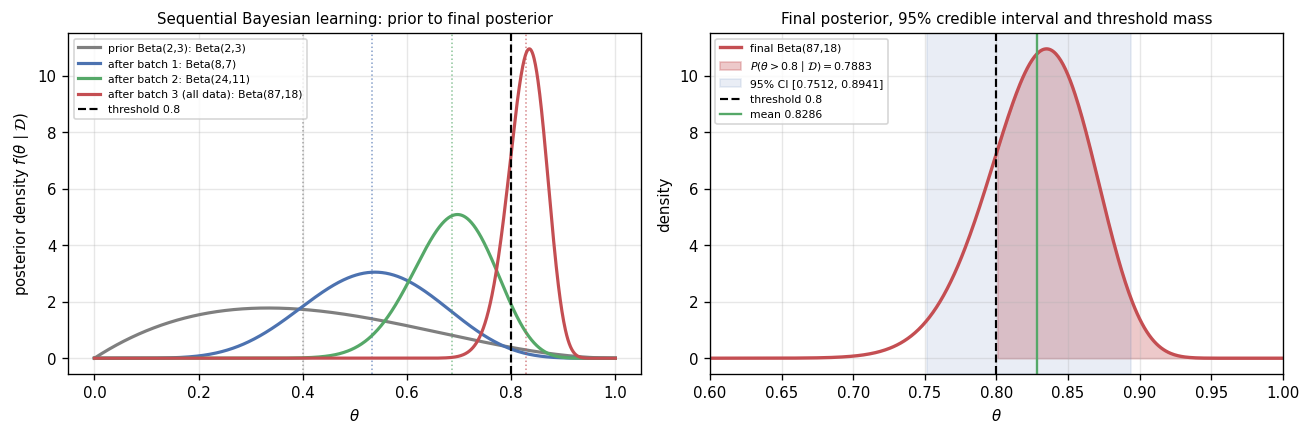

In [6]:
# --------------------------------------- plot prior and all three posteriors
th = np.linspace(0, 1, 1200)
labels = ["prior Beta(2,3)", "after batch 1", "after batch 2", "after batch 3 (all data)"]
colours = ["#7f7f7f", "#4C72B0", "#55A868", "#C44E52"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))

ax = axes[0]
for (aa, bb), lab, c in zip(seq_params, labels, colours):
    ax.plot(th, stats.beta(aa, bb).pdf(th), color=c, lw=1.9,
            label=f"{lab}: Beta({aa:g},{bb:g})")
    ax.axvline(aa / (aa + bb), color=c, ls=":", lw=0.9, alpha=0.7)
ax.axvline(THRESHOLD, color="black", ls="--", lw=1.3, label=f"threshold {THRESHOLD}")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"posterior density $f(\theta \mid \mathcal{D})$")
ax.set_title("Sequential Bayesian learning: prior to final posterior", fontsize=9)
ax.legend(fontsize=6.5, loc="upper left")

ax = axes[1]
ax.plot(th, POST.pdf(th), color="#C44E52", lw=2, label=f"final Beta({A_FINAL:g},{B_FINAL:g})")
mask = th > THRESHOLD
ax.fill_between(th[mask], 0, POST.pdf(th[mask]), color="#C44E52", alpha=0.30,
                label=fr"$P(\theta>0.8\mid\mathcal{{D}}) = {POST.sf(THRESHOLD):.4f}$")
lo, hi = POST.ppf(0.025), POST.ppf(0.975)
ax.axvspan(lo, hi, color="#4C72B0", alpha=0.12, label=f"95% CI [{lo:.4f}, {hi:.4f}]")
ax.axvline(THRESHOLD, color="black", ls="--", lw=1.3, label=f"threshold {THRESHOLD}")
ax.axvline(POST.mean(), color="#55A868", lw=1.4, label=f"mean {POST.mean():.4f}")
ax.set_xlim(0.6, 1.0)
ax.set_xlabel(r"$\theta$"); ax.set_ylabel("density")
ax.set_title("Final posterior, 95% credible interval and threshold mass", fontsize=9)
ax.legend(fontsize=6.5, loc="upper left")

plt.tight_layout()
plt.savefig(os.path.join(RES, "B2_posterior_evolution.png"), bbox_inches="tight")
plt.show()

In [7]:
# --------------------------------------- estimate table (report version)
est = seq_df[["stage", "cum_attempts", "cum_successes", "ML (s/n)",
              "posterior mean", "MAP (mode)", "posterior sd"]].copy()
print("CUMULATIVE POINT ESTIMATES AFTER EACH BATCH\n")
print(est.to_string(index=False))
est.to_csv(os.path.join(RES, "B2_point_estimates.csv"), index=False)
with open(os.path.join(RES, "B2_point_estimates.md"), "w") as f:
    f.write(est.to_markdown(index=False, floatfmt=".4f"))

print("\nThe three estimators converge as data accumulates: the prior's pull is strongest after "
      "batch 1 (10 attempts vs a prior worth ~3) and nearly negligible after batch 3 (100 "
      "attempts). ML ignores the prior entirely; the posterior mean is pulled toward the prior "
      "mean 0.4; MAP sits between them because the mode of a left-skewed posterior lies above "
      "its mean.")
print(f"\ngap |posterior mean - ML| : batch1 = "
      f"{abs(est['posterior mean'][1]-est['ML (s/n)'][1]):.4f}, "
      f"batch3 = {abs(est['posterior mean'][3]-est['ML (s/n)'][3]):.4f}")

CUMULATIVE POINT ESTIMATES AFTER EACH BATCH

          stage  cum_attempts  cum_successes  ML (s/n)  posterior mean  MAP (mode)  posterior sd
prior Beta(2,3)             0              0       NaN        0.400000    0.333333      0.200000
  after batch 1            10              6  0.600000        0.533333    0.538462      0.124722
  after batch 2            30             22  0.733333        0.685714    0.696970      0.077372
  after batch 3           100             85  0.850000        0.828571    0.834951      0.036606

The three estimators converge as data accumulates: the prior's pull is strongest after batch 1 (10 attempts vs a prior worth ~3) and nearly negligible after batch 3 (100 attempts). ML ignores the prior entirely; the posterior mean is pulled toward the prior mean 0.4; MAP sits between them because the mode of a left-skewed posterior lies above its mean.

gap |posterior mean - ML| : batch1 = 0.0667, batch3 = 0.0214


## B3. Quantify uncertainty and make a decision

### The three quantities, and why they are different

**1. Posterior predictive probability of success on the next attempt.** We do not know $\theta$, so
we average the Bernoulli success probability over the whole posterior rather than plugging in a point
estimate:

$$P(X_{n+1} = 1 \mid \mathcal{D}) = \int_0^1 \underbrace{P(X_{n+1}=1\mid\theta)}_{=\;\theta} f(\theta\mid\mathcal{D})\, d\theta
= \mathbb{E}[\theta \mid \mathcal{D}] = \frac{\alpha_n}{\alpha_n+\beta_n}$$

For the Beta–Bernoulli pair this integral happens to equal the posterior mean, which is why the two
numbers coincide. They are conceptually distinct all the same: one is a probability about a future
*observation*, the other a summary of a *parameter* distribution. Predictions about future data have
to integrate over parameter uncertainty; the coincidence is a property of the linear expectation, and
it disappears for any non-linear quantity (e.g. the probability that the next **two** attempts both
succeed is $\mathbb{E}[\theta^2] > (\mathbb{E}[\theta])^2$ by Jensen's inequality — strictly larger
than the plug-in answer).

**2. A 95% equal-tailed credible interval.** The values $[\theta_{0.025},\ \theta_{0.975}]$ from the
posterior quantile function, leaving 2.5% probability in each tail. Read directly: given the model,
the prior and the data, there is a 95% posterior probability that $\theta$ lies in this interval.

**3. $P(\theta > 0.8 \mid \mathcal{D})$.** The posterior *mass* above the threshold — the survival
function $1 - F(0.8)$, i.e. the shaded area in the B2 figure. This is the quantity the deployment
rule refers to.

In [8]:
predictive = A_FINAL / (A_FINAL + B_FINAL)
ci_lo, ci_hi = POST.ppf(0.025), POST.ppf(0.975)
p_gt = POST.sf(THRESHOLD)

print("USING ALL THREE BATCHES  (posterior "
      f"Beta({A_FINAL:g}, {B_FINAL:g}), n = {TOTAL_N}, s = {TOTAL_S})\n")
print(f"1. posterior predictive P(X_next = 1 | D) = {predictive:.6f}")
print(f"     (= posterior mean {POST.mean():.6f}; ML plug-in would give "
      f"{TOTAL_S/TOTAL_N:.6f})")
print(f"2. 95% equal-tailed credible interval    = [{ci_lo:.6f}, {ci_hi:.6f}]  "
      f"(width {ci_hi-ci_lo:.6f})")
print(f"3. P(theta > {THRESHOLD} | D)                  = {p_gt:.6f}")

# independent checks on each quantity ------------------------------------------------
print("\n--- independent numerical checks ---")
pred_int = integrate.quad(lambda t: t * POST.pdf(t), 0, 1)[0]
print(f"predictive via numerical integral of theta*f(theta): {pred_int:.8f}  "
      f"(closed form {predictive:.8f})")
print(f"CDF check: F(ci_lo) = {POST.cdf(ci_lo):.6f} (want 0.025), "
      f"F(ci_hi) = {POST.cdf(ci_hi):.6f} (want 0.975)")
sf_int = integrate.quad(POST.pdf, THRESHOLD, 1)[0]
print(f"P(theta>0.8) via numerical integral: {sf_int:.8f}  (scipy sf {p_gt:.8f})")
print(f"1 - cdf(0.8) = {1 - POST.cdf(THRESHOLD):.8f}")

USING ALL THREE BATCHES  (posterior Beta(87, 18), n = 100, s = 85)

1. posterior predictive P(X_next = 1 | D) = 0.828571
     (= posterior mean 0.828571; ML plug-in would give 0.850000)
2. 95% equal-tailed credible interval    = [0.751232, 0.894076]  (width 0.142844)
3. P(theta > 0.8 | D)                  = 0.788267

--- independent numerical checks ---
predictive via numerical integral of theta*f(theta): 0.82857143  (closed form 0.82857143)
CDF check: F(ci_lo) = 0.025000 (want 0.025), F(ci_hi) = 0.975000 (want 0.975)
P(theta>0.8) via numerical integral: 0.78826666  (scipy sf 0.78826666)
1 - cdf(0.8) = 0.78826666


MONTE-CARLO VERIFICATION   (seed = 20260910, draws = 200,000)

  analytic  P(theta > 0.8 | D) = 0.788267
  simulated P(theta > 0.8 | D) = 0.786880   (standard error 0.000916)
  |difference|                 = 0.001387  = 1.51 standard errors

  MC posterior mean = 0.828497 vs analytic 0.828571
  MC 95% CI         = [0.751054, 0.894043] vs analytic [0.751232, 0.894076]

 draws  MC estimate  abs error vs analytic
  1000      0.77300               0.015267
 10000      0.78960               0.001333
 50000      0.78602               0.002247
100000      0.78700               0.001267
200000      0.78688               0.001387


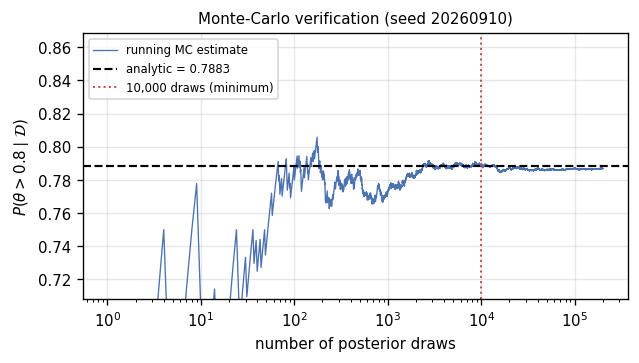

In [9]:
# ------------------- Monte-Carlo verification of P(theta > 0.8 | D) with a stated seed
rng_mc = np.random.default_rng(SEED)
draws = rng_mc.beta(A_FINAL, B_FINAL, N_DRAWS)

mc_p = float((draws > THRESHOLD).mean())
mc_se = float(np.sqrt(mc_p * (1 - mc_p) / N_DRAWS))
print(f"MONTE-CARLO VERIFICATION   (seed = {SEED}, draws = {N_DRAWS:,})\n")
print(f"  analytic  P(theta > 0.8 | D) = {p_gt:.6f}")
print(f"  simulated P(theta > 0.8 | D) = {mc_p:.6f}   (standard error {mc_se:.6f})")
print(f"  |difference|                 = {abs(mc_p - p_gt):.6f}  "
      f"= {abs(mc_p - p_gt)/mc_se:.2f} standard errors")
print(f"\n  MC posterior mean = {draws.mean():.6f} vs analytic {POST.mean():.6f}")
print(f"  MC 95% CI         = [{np.quantile(draws, 0.025):.6f}, "
      f"{np.quantile(draws, 0.975):.6f}] vs analytic [{ci_lo:.6f}, {ci_hi:.6f}]")

# convergence of the MC estimate, and the required minimum of 10,000 draws
sizes = [1_000, 10_000, 50_000, 100_000, 200_000]
conv = pd.DataFrame([{"draws": m, "MC estimate": draws[:m].mean() * 0 + (draws[:m] > THRESHOLD).mean(),
                      "abs error vs analytic": abs((draws[:m] > THRESHOLD).mean() - p_gt)}
                     for m in sizes])
print("\n" + conv.to_string(index=False))
conv.to_csv(os.path.join(RES, "B3_mc_convergence.csv"), index=False)

fig, ax = plt.subplots(figsize=(5.4, 3.1))
running = np.cumsum(draws > THRESHOLD) / np.arange(1, N_DRAWS + 1)
ax.plot(np.arange(1, N_DRAWS + 1), running, lw=0.8, color="#4C72B0",
        label="running MC estimate")
ax.axhline(p_gt, color="black", ls="--", lw=1.3, label=f"analytic = {p_gt:.4f}")
ax.axvline(10_000, color="#C44E52", ls=":", lw=1.2, label="10,000 draws (minimum)")
ax.set_xscale("log"); ax.set_xlabel("number of posterior draws")
ax.set_ylabel(r"$P(\theta > 0.8 \mid \mathcal{D})$")
ax.set_ylim(p_gt - 0.08, p_gt + 0.08)
ax.set_title(f"Monte-Carlo verification (seed {SEED})", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(RES, "B3_mc_verification.png"), bbox_inches="tight")
plt.show()

In [10]:
# ----------------------------------------------------- the deployment decision
meets = p_gt >= DECISION_LEVEL
print("=" * 66)
print(f"DEPLOYMENT RULE:  require P(theta > {THRESHOLD} | D) >= {DECISION_LEVEL}")
print("=" * 66)
print(f"  observed             : P(theta > 0.8 | D) = {p_gt:.4f}")
print(f"  required             : {DECISION_LEVEL}")
print(f"  shortfall            : {DECISION_LEVEL - p_gt:.4f}")
print(f"  DECISION             : {'MET -> deploy' if meets else 'NOT MET -> do not deploy yet'}")
print(f"\n  for context: ML estimate = {TOTAL_S/TOTAL_N:.4f} and posterior mean = "
      f"{POST.mean():.4f}, both ABOVE 0.8,")
print(f"  yet the rule still fails, and the 95% CI lower bound is {ci_lo:.4f} < 0.8.")

# How much more data would be needed, at the same observed success rate?
print("\nHow many additional attempts at the SAME observed rate (0.85) would satisfy the rule?")
rate = TOTAL_S / TOTAL_N
for extra in [0, 50, 100, 200, 300, 400, 500, 700]:
    s_ex = int(round(rate * extra))
    aa, bb = A_FINAL + s_ex, B_FINAL + (extra - s_ex)
    pv = stats.beta(aa, bb).sf(THRESHOLD)
    flag = "  <-- rule satisfied" if pv >= DECISION_LEVEL else ""
    print(f"  +{extra:4d} attempts (+{s_ex:3d} successes) -> Beta({aa:6.1f},{bb:5.1f})  "
          f"P(theta>0.8) = {pv:.4f}{flag}")

decision = {"P(theta>0.8|D)": float(p_gt), "required": DECISION_LEVEL,
            "meets_rule": bool(meets), "posterior_mean": float(POST.mean()),
            "ML": float(TOTAL_S / TOTAL_N), "CI": [float(ci_lo), float(ci_hi)],
            "predictive_next": float(predictive),
            "mc_estimate": mc_p, "mc_seed": SEED, "mc_draws": N_DRAWS}
with open(os.path.join(RES, "B3_decision.json"), "w") as f:
    json.dump(decision, f, indent=2)

DEPLOYMENT RULE:  require P(theta > 0.8 | D) >= 0.95
  observed             : P(theta > 0.8 | D) = 0.7883
  required             : 0.95
  shortfall            : 0.1617
  DECISION             : NOT MET -> do not deploy yet

  for context: ML estimate = 0.8500 and posterior mean = 0.8286, both ABOVE 0.8,
  yet the rule still fails, and the 95% CI lower bound is 0.7512 < 0.8.

How many additional attempts at the SAME observed rate (0.85) would satisfy the rule?
  +   0 attempts (+  0 successes) -> Beta(  87.0, 18.0)  P(theta>0.8) = 0.7883
  +  50 attempts (+ 42 successes) -> Beta( 129.0, 26.0)  P(theta>0.8) = 0.8580
  + 100 attempts (+ 85 successes) -> Beta( 172.0, 33.0)  P(theta>0.8) = 0.9299
  + 200 attempts (+170 successes) -> Beta( 257.0, 48.0)  P(theta>0.8) = 0.9744  <-- rule satisfied
  + 300 attempts (+255 successes) -> Beta( 342.0, 63.0)  P(theta>0.8) = 0.9902  <-- rule satisfied
  + 400 attempts (+340 successes) -> Beta( 427.0, 78.0)  P(theta>0.8) = 0.9962  <-- rule satisfied
  +

In [11]:
# Why a PDF value at 0.8 is NOT the probability -- demonstrated numerically.
print("A DENSITY VALUE IS NOT A PROBABILITY\n")
print(f"  f(0.8)                     = {POST.pdf(THRESHOLD):.6f}   <- a density; can exceed 1")
print(f"  P(theta > 0.8 | D)         = {p_gt:.6f}   <- the required probability (an area)")
print(f"  P(theta = 0.8 | D)         = 0 exactly    <- a point has zero probability")
print(f"\n  f(0.8) integrates to a probability only over an interval, e.g.")
for w in (0.01, 0.001):
    exact_w = POST.cdf(THRESHOLD + w / 2) - POST.cdf(THRESHOLD - w / 2)
    print(f"    P(0.8 +/- {w/2:.4f}) = {exact_w:.6f}   ~= f(0.8) * {w} = "
          f"{POST.pdf(THRESHOLD)*w:.6f}")
print(f"\n  Densities can even exceed 1: max of this posterior is "
      f"{POST.pdf(np.linspace(0,1,10001)).max():.3f} at theta = "
      f"{(A_FINAL-1)/(A_FINAL+B_FINAL-2):.4f}")

A DENSITY VALUE IS NOT A PROBABILITY

  f(0.8)                     = 7.255623   <- a density; can exceed 1
  P(theta > 0.8 | D)         = 0.788267   <- the required probability (an area)
  P(theta = 0.8 | D)         = 0 exactly    <- a point has zero probability

  f(0.8) integrates to a probability only over an interval, e.g.
    P(0.8 +/- 0.0050) = 0.072540   ~= f(0.8) * 0.01 = 0.072556
    P(0.8 +/- 0.0005) = 0.007256   ~= f(0.8) * 0.001 = 0.007256

  Densities can even exceed 1: max of this posterior is 10.957 at theta = 0.8350


### Does the evidence meet the deployment rule?

**No.** The posterior probability $P(\theta > 0.8 \mid \mathcal{D})$ computed above falls short of
the required $0.95$. The rule is not
satisfied and the robot should not be deployed on this evidence.

**Why a point estimate above 0.8 is not sufficient.** Both the maximum-likelihood estimate
$85/100 = 0.85$ and the posterior mean lie *above* the threshold, yet the rule still fails. A point
estimate is a single summary of the posterior and discards its width. With only 100 attempts the
posterior still has a visible spread, and a substantial slice of it lies below $0.8$ — so a
non-trivial probability remains that the true reliability is below the standard. The deployment rule
is deliberately written about the *whole posterior distribution*, not its centre, because the cost of
deploying an unreliable gripper is borne when $\theta$ turns out to be low, not when the average
looks acceptable. The 95% credible interval makes the same point: its lower bound sits below $0.8$,
so $\theta < 0.8$ has not been ruled out at that level. Passing the rule requires the posterior to be
*concentrated* above the threshold, which needs more data (the table above shows roughly how many
further attempts at the same observed success rate would be required).

**Why a PDF value at 0.8 is not this probability.** $f(0.8)$ is a *density*: a limiting
probability-per-unit-$\theta$, not a probability. It can be any non-negative number, including values
above 1 (this posterior peaks above 10), so it cannot be compared to $0.95$ at all. The probability
of any single point is exactly zero for a continuous parameter. The quantity the rule needs is the
*area* under the density to the right of the threshold,
$P(\theta > 0.8\mid\mathcal{D}) = \int_{0.8}^{1} f(\theta\mid\mathcal{D})\,d\theta = 1 - F(0.8)$,
which is what `sf(0.8)` returns and what the Monte-Carlo draws confirm to within the reported
standard error. The cell above verifies the relationship explicitly: $f(0.8)$ times a small width
approximates the probability of that narrow interval, which is what a density means.

## B4. Examine the role of the prior

Three priors, all in the same conjugate family, compared after Batch 1 alone (10 attempts) and after
all three batches (100 attempts):

| Prior | Interpretation | Prior mean | Prior "pseudo-attempts" $\alpha+\beta$ |
|---|---|---|---|
| $\mathrm{Beta}(2,3)$ | the assignment's mildly pessimistic prior | $0.400$ | 5 |
| $\mathrm{Beta}(1,1)$ | uniform — flat over $(0,1)$, "no preference" | $0.500$ | 2 |
| $\mathrm{Beta}(8,2)$ | optimistic — believes the gripper is already good | $0.800$ | 10 |

In [12]:
PRIORS = [("Beta(2,3) [assignment]", 2.0, 3.0),
          ("Beta(1,1) [uniform]",    1.0, 1.0),
          ("Beta(8,2) [optimistic]", 8.0, 2.0)]

rows = []
for name, a0, b0 in PRIORS:
    for stage, n_c, s_c in [("prior only", 0, 0),
                            ("after batch 1", BATCHES[0]["n"], BATCHES[0]["s"]),
                            ("after all batches", TOTAL_N, TOTAL_S)]:
        aa, bb = a0 + s_c, b0 + (n_c - s_c)
        d = stats.beta(aa, bb)
        mode = (aa - 1) / (aa + bb - 2) if (aa > 1 and bb > 1) else np.nan
        rows.append({"prior": name, "stage": stage,
                     "alpha": aa, "beta": bb,
                     "ML (s/n)": (s_c / n_c) if n_c else np.nan,
                     "posterior mean": aa / (aa + bb),
                     "MAP (mode)": mode,
                     "P(theta > 0.8)": d.sf(THRESHOLD),
                     "95% CI low": d.ppf(0.025), "95% CI high": d.ppf(0.975),
                     "posterior sd": d.std(),
                     "meets rule": d.sf(THRESHOLD) >= DECISION_LEVEL})

sens = pd.DataFrame(rows)
print("PRIOR SENSITIVITY\n")
print(sens.to_string(index=False))
sens.to_csv(os.path.join(RES, "B4_prior_sensitivity.csv"), index=False)

focus = sens[sens.stage != "prior only"][
    ["prior", "stage", "ML (s/n)", "posterior mean", "MAP (mode)",
     "P(theta > 0.8)", "meets rule"]]
with open(os.path.join(RES, "B4_prior_sensitivity.md"), "w") as f:
    f.write(focus.to_markdown(index=False, floatfmt=".4f"))

print("\n--- spread across the three priors ---")
for stage in ["after batch 1", "after all batches"]:
    s = sens[sens.stage == stage]
    print(f"{stage:20s}: posterior mean range = "
          f"{s['posterior mean'].min():.4f} to {s['posterior mean'].max():.4f} "
          f"(spread {s['posterior mean'].max()-s['posterior mean'].min():.4f}); "
          f"P(theta>0.8) range = {s['P(theta > 0.8)'].min():.4f} to "
          f"{s['P(theta > 0.8)'].max():.4f}")

PRIOR SENSITIVITY

                 prior             stage  alpha  beta  ML (s/n)  posterior mean  MAP (mode)  P(theta > 0.8)  95% CI low  95% CI high  posterior sd  meets rule
Beta(2,3) [assignment]        prior only    2.0   3.0       NaN        0.400000    0.333333        0.027200    0.067586     0.805880      0.200000       False
Beta(2,3) [assignment]     after batch 1    8.0   7.0      0.60        0.533333    0.538462        0.011610    0.288609     0.769639      0.124722       False
Beta(2,3) [assignment] after all batches   87.0  18.0      0.85        0.828571    0.834951        0.788267    0.751232     0.894076      0.036606       False
   Beta(1,1) [uniform]        prior only    1.0   1.0       NaN        0.500000         NaN        0.200000    0.025000     0.975000      0.288675       False
   Beta(1,1) [uniform]     after batch 1    7.0   5.0      0.60        0.583333    0.600000        0.050410    0.307905     0.832512      0.136735       False
   Beta(1,1) [uniform] afte

In [13]:
# --------------------- ML vs MAP under a uniform prior
print("ML AND MAP UNDER THE UNIFORM PRIOR Beta(1,1)\n")
for stage, n_c, s_c in [("after batch 1", BATCHES[0]["n"], BATCHES[0]["s"]),
                        ("after all batches", TOTAL_N, TOTAL_S)]:
    aa, bb = 1.0 + s_c, 1.0 + (n_c - s_c)
    mode = (aa - 1) / (aa + bb - 2)
    ml = s_c / n_c
    mean = aa / (aa + bb)
    print(f"{stage:20s}  ML = {ml:.6f}   MAP = {mode:.6f}   "
          f"identical: {np.isclose(ml, mode)}   posterior mean = {mean:.6f} (differs)")

print("\nAlgebraically, with alpha = beta = 1 the posterior is Beta(1+s, 1+n-s), so")
print("   MAP = (alpha-1)/(alpha+beta-2) = s/n = ML,")
print("because a flat prior contributes no theta-dependence: maximising the posterior reduces to")
print("maximising the likelihood. The posterior MEAN is (1+s)/(2+n) = Laplace smoothing, which is")
print("NOT equal to s/n -- it is pulled toward 0.5 by the prior's two pseudo-attempts.")

# Show the practical difference: an extreme dataset
print("\nWhy the full Bayesian answer still differs from ML -- an extreme case (n=5, s=5):")
n_x, s_x = 5, 5
d_x = stats.beta(1 + s_x, 1 + n_x - s_x)
print(f"   ML                     = {s_x/n_x:.4f}   -> claims the next attempt CANNOT fail")
print(f"   MAP (uniform prior)    = {s_x/n_x:.4f}   -> same point estimate")
print(f"   posterior predictive   = {d_x.mean():.4f}   -> admits failure is still possible")
print(f"   95% CI                 = [{d_x.ppf(0.025):.4f}, {d_x.ppf(0.975):.4f}]  "
      "-> ML reports no interval at all")
print(f"   P(theta > 0.8)         = {d_x.sf(0.8):.4f}   -> ML cannot express this quantity")

ML AND MAP UNDER THE UNIFORM PRIOR Beta(1,1)

after batch 1         ML = 0.600000   MAP = 0.600000   identical: True   posterior mean = 0.583333 (differs)
after all batches     ML = 0.850000   MAP = 0.850000   identical: True   posterior mean = 0.843137 (differs)

Algebraically, with alpha = beta = 1 the posterior is Beta(1+s, 1+n-s), so
   MAP = (alpha-1)/(alpha+beta-2) = s/n = ML,
because a flat prior contributes no theta-dependence: maximising the posterior reduces to
maximising the likelihood. The posterior MEAN is (1+s)/(2+n) = Laplace smoothing, which is
NOT equal to s/n -- it is pulled toward 0.5 by the prior's two pseudo-attempts.

Why the full Bayesian answer still differs from ML -- an extreme case (n=5, s=5):
   ML                     = 1.0000   -> claims the next attempt CANNOT fail
   MAP (uniform prior)    = 1.0000   -> same point estimate
   posterior predictive   = 0.8571   -> admits failure is still possible
   95% CI                 = [0.5407, 0.9958]  -> ML reports n

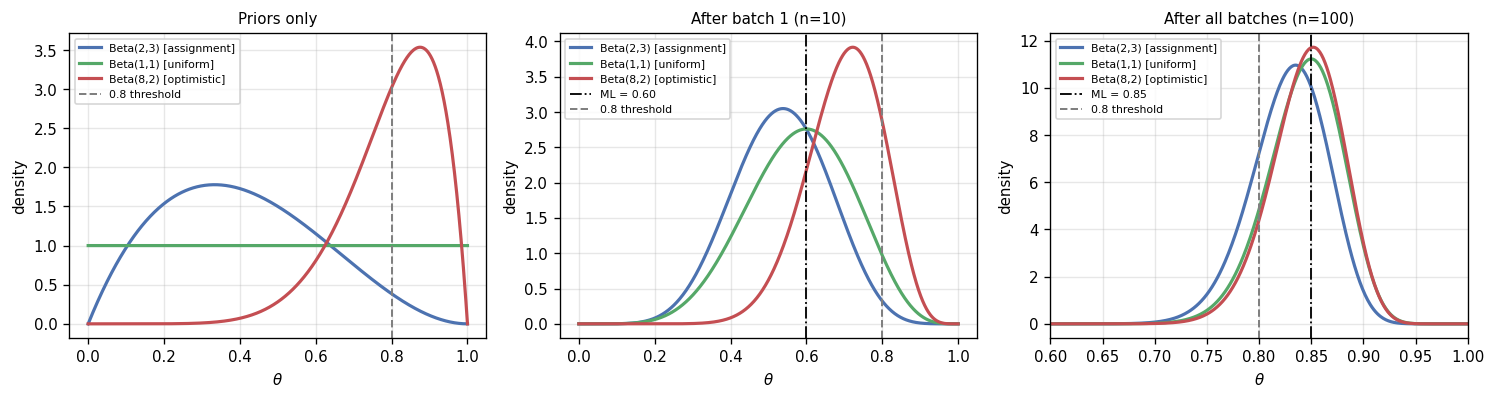

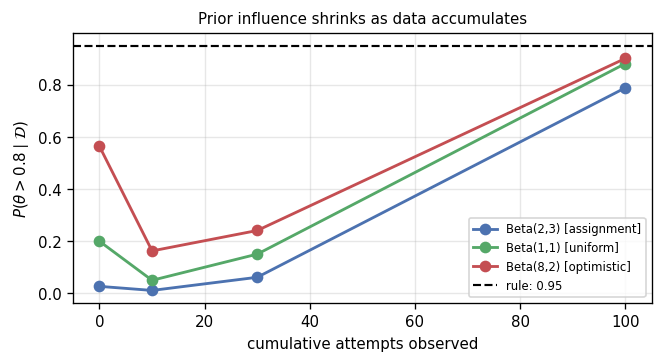

In [14]:
# --------------------- visualise prior sensitivity
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
th = np.linspace(0, 1, 1200)
pcolours = ["#4C72B0", "#55A868", "#C44E52"]

for ax, (stage, n_c, s_c) in zip(axes, [("Priors only", 0, 0),
                                        ("After batch 1 (n=10)", 10, 6),
                                        ("After all batches (n=100)", TOTAL_N, TOTAL_S)]):
    for (name, a0, b0), c in zip(PRIORS, pcolours):
        aa, bb = a0 + s_c, b0 + (n_c - s_c)
        ax.plot(th, stats.beta(aa, bb).pdf(th), color=c, lw=1.9, label=name)
    if n_c:
        ax.axvline(s_c / n_c, color="black", ls="-.", lw=1.1, label=f"ML = {s_c/n_c:.2f}")
    ax.axvline(THRESHOLD, color="grey", ls="--", lw=1.2, label="0.8 threshold")
    ax.set_title(stage, fontsize=9)
    ax.set_xlabel(r"$\theta$"); ax.set_ylabel("density")
    ax.legend(fontsize=6.5)
    if n_c == TOTAL_N:
        ax.set_xlim(0.6, 1.0)

plt.tight_layout()
plt.savefig(os.path.join(RES, "B4_prior_sensitivity.png"), bbox_inches="tight")
plt.show()

# threshold probability as a function of prior strength, at fixed data
fig, ax = plt.subplots(figsize=(5.6, 3.1))
for (name, a0, b0), c in zip(PRIORS, pcolours):
    xs, ys = [], []
    for n_c, s_c in [(0, 0), (10, 6), (30, 22), (100, 85)]:
        xs.append(n_c)
        ys.append(stats.beta(a0 + s_c, b0 + n_c - s_c).sf(THRESHOLD))
    ax.plot(xs, ys, marker="o", color=c, lw=1.7, label=name)
ax.axhline(DECISION_LEVEL, color="black", ls="--", lw=1.3, label="rule: 0.95")
ax.set_xlabel("cumulative attempts observed")
ax.set_ylabel(r"$P(\theta > 0.8 \mid \mathcal{D})$")
ax.set_title("Prior influence shrinks as data accumulates", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(RES, "B4_prior_influence_vs_data.png"), bbox_inches="tight")
plt.show()

### Interpreting prior sensitivity

**After Batch 1 the prior matters; after all batches it barely does.** With only 10 attempts the
three priors are worth 5, 2 and 10 pseudo-attempts respectively — comparable to the data itself — so
the posterior means are visibly spread and the optimistic $\mathrm{Beta}(8,2)$ gives a much larger
$P(\theta > 0.8)$ than the other two. After 100 attempts the data term dominates every prior: the
posterior means collapse into a narrow band, all three sit close to the ML value $0.85$. This is the usual asymptotic picture — the
likelihood accumulates with $n$ while a fixed prior does not — and it is the practical reason to
report prior sensitivity rather than to argue about the "correct" prior: if a conclusion flips
between reasonable priors, the data are too weak to support it.

The threshold probability is more prior-sensitive than the mean, because it depends on the posterior
*tail* rather than its centre. That is worth noting for the deployment rule specifically: a decision
stated as a tail probability is more fragile under prior choice than one stated as a point estimate.
Whether the rule is met under each prior is recorded in the `meets rule` column.

**ML and MAP under a uniform prior.** With $\mathrm{Beta}(1,1)$ the prior density is constant, so it
contributes nothing that depends on $\theta$:
$f(\theta\mid\mathcal{D}) \propto P(\mathcal{D}\mid\theta) \cdot 1$. Maximising the posterior is then
literally maximising the likelihood, and the algebra confirms it:
$\hat\theta_{\mathrm{MAP}} = \frac{(1+s)-1}{(1+s)+(1+n-s)-2} = \frac{s}{n} = \hat\theta_{\mathrm{ML}}$.
The cell above verifies this equality numerically at both stages.

**Why that does not make the Bayesian answer identical to ML.** The coincidence is only about the
*single point* where the density is highest — MAP and ML pick the same mode. Everything else differs:

* The **posterior mean** under $\mathrm{Beta}(1,1)$ is $(1+s)/(2+n)$, i.e. Laplace-smoothed, not
  $s/n$. It is the posterior predictive probability for the next attempt, so even the flat-prior
  Bayesian *prediction* differs from the ML plug-in.
* ML returns a number; the posterior returns a **distribution**, from which credible intervals and
  $P(\theta > 0.8\mid\mathcal{D})$ follow. ML has no mechanism to produce the quantity the deployment
  rule asks for — a frequentist confidence interval is a different object with a different
  interpretation.
* The gap matters most exactly where decisions are riskiest. The extreme example above ($5$ successes
  in $5$ attempts) makes it concrete: ML and MAP both say $\hat\theta = 1.0$, implying the next
  attempt cannot possibly fail, while the flat-prior posterior predictive gives about $0.86$ and
  assigns real probability to failure. Optimising a point and carrying a distribution are different
  operations; only the second one propagates uncertainty into the decision.

In [15]:
# ------------------------------------------------------------------ manifest
manifest = {
    "part": "B",
    "student": {"name": "Satria Pamungkas", "id": "21522611"},
    "model": {"likelihood": "Bernoulli(theta)", "prior": "Beta(2,3)",
              "conjugate_update": "Beta(alpha+s, beta+n-s)"},
    "data_batches": BATCHES, "pooled": {"n": TOTAL_N, "s": TOTAL_S},
    "final_posterior": {"alpha": A_FINAL, "beta": B_FINAL,
                        "mean": float(POST.mean()), "sd": float(POST.std()),
                        "MAP": float((A_FINAL-1)/(A_FINAL+B_FINAL-2))},
    "B3": decision,
    "seeds": {"numpy_default_rng": SEED, "posterior_draws": N_DRAWS},
    "priors_compared": [{"name": n, "alpha": a, "beta": b} for n, a, b in PRIORS],
    "environment": {"python": sys.version.split()[0], "numpy": np.__version__,
                    "scipy": __import__("scipy").__version__,
                    "platform": platform.platform()},
    "files": sorted(os.listdir(RES)),
}
with open(os.path.join(RES, "B_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

print("KEY NUMBERS FOR THE REPORT")
print("=" * 50)
print(f"final posterior          Beta({A_FINAL:g}, {B_FINAL:g})")
print(f"posterior mean           {POST.mean():.4f}")
print(f"MAP                      {(A_FINAL-1)/(A_FINAL+B_FINAL-2):.4f}")
print(f"ML                       {TOTAL_S/TOTAL_N:.4f}")
print(f"predictive next success  {predictive:.4f}")
print(f"95% credible interval    [{ci_lo:.4f}, {ci_hi:.4f}]")
print(f"P(theta > 0.8 | D)       {p_gt:.4f}   (MC {mc_p:.4f})")
print(f"deployment rule met?     {'YES' if meets else 'NO'}")
print("\nPart B complete. Artefacts written to:", RES)
for fn in sorted(os.listdir(RES)):
    print("  ", fn)

KEY NUMBERS FOR THE REPORT
final posterior          Beta(87, 18)
posterior mean           0.8286
MAP                      0.8350
ML                       0.8500
predictive next success  0.8286
95% credible interval    [0.7512, 0.8941]
P(theta > 0.8 | D)       0.7883   (MC 0.7869)
deployment rule met?     NO

Part B complete. Artefacts written to: /home/21522611/Documents/PHUIML-Assignment/results/partB
   B2_point_estimates.csv
   B2_point_estimates.md
   B2_posterior_evolution.png
   B2_sequential_updates.csv
   B3_decision.json
   B3_mc_convergence.csv
   B3_mc_verification.png
   B4_prior_influence_vs_data.png
   B4_prior_sensitivity.csv
   B4_prior_sensitivity.md
   B4_prior_sensitivity.png
   B_manifest.json
